### Segundo parcial inferencia estadística y reconocimiento de patrones. 

### Alumnas: Parallela Luciana Sol y Gonzalez Camila Belén. 

### Algoritmo Kmeans.

In [65]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder 
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import pairwise_distances_argmin_min
from sklearn.metrics import silhouette_score, calinski_harabasz_score, davies_bouldin_score 
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)
pd.set_option("display.max_colwidth", None)

In [66]:
df = pd.read_csv(r"C:\Users\ASUS\OneDrive\Desktop\Segundo parcial inferencia estadística\Live_20210128.csv")
df.head(6)

,status_id,status_type,status_published,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys,Column1,Column2,Column3,Column4
0,1,video,4/22/2018 6:00,529,512,262,432,92,3,1,1,0,NaN,NaN,NaN,NaN
1,2,photo,4/21/2018 22:45,150,0,0,150,0,0,0,0,0,NaN,NaN,NaN,NaN
2,3,video,4/21/2018 6:17,227,236,57,204,21,1,1,0,0,NaN,NaN,NaN,NaN
3,4,photo,4/21/2018 2:29,111,0,0,111,0,0,0,0,0,NaN,NaN,NaN,NaN
4,5,photo,4/18/2018 3:22,213,0,0,204,9,0,0,0,0,NaN,NaN,NaN,NaN
5,6,photo,4/18/2018 2:14,217,6,0,211,5,1,0,0,0,NaN,NaN,NaN,NaN


## Realizamos análisis exploratorio:
1. Nombres de las columnas.
2. Cuantas filas tenemos y el total de datos.
3. Cuantos valores nulos tenemos.


In [67]:
df.columns 

Index(['status_id', 'status_type', 'status_published', 'num_reactions',
       'num_comments', 'num_shares', 'num_likes', 'num_loves', 'num_wows',
       'num_hahas', 'num_sads', 'num_angrys', 'Column1', 'Column2', 'Column3',
       'Column4'],
      dtype='object')

In [68]:
df.shape

(7050, 16)

Vemos que las ultimas 4 columnas están compuestas únicamente por valores nulos, por eso decidimos eliminarlas. Además decidimos eliminar la columna "status_pusblished" que 
corresponde a las fechas y la columna "status_id". 


In [69]:
datos = df[['status_type', 'num_reactions',
       'num_comments', 'num_shares', 'num_likes', 'num_loves', 'num_wows',
       'num_hahas', 'num_sads', 'num_angrys']]

In [70]:
for column in datos.columns:
    unique_values = datos[column].unique()
    print(f"Columna: {column}")
    #print(f"Valores únicos: {unique_values}")
    print(f"Número de valores únicos: {len(unique_values)}")
    print("-" * 40)

Columna: status_type
Número de valores únicos: 4
----------------------------------------
Columna: num_reactions
Número de valores únicos: 1067
----------------------------------------
Columna: num_comments
Número de valores únicos: 993
----------------------------------------
Columna: num_shares
Número de valores únicos: 501
----------------------------------------
Columna: num_likes
Número de valores únicos: 1044
----------------------------------------
Columna: num_loves
Número de valores únicos: 229
----------------------------------------
Columna: num_wows
Número de valores únicos: 65
----------------------------------------
Columna: num_hahas
Número de valores únicos: 42
----------------------------------------
Columna: num_sads
Número de valores únicos: 24
----------------------------------------
Columna: num_angrys
Número de valores únicos: 14
----------------------------------------


In [71]:
datos.head(6)

,status_type,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys
0,video,529,512,262,432,92,3,1,1,0
1,photo,150,0,0,150,0,0,0,0,0
2,video,227,236,57,204,21,1,1,0,0
3,photo,111,0,0,111,0,0,0,0,0
4,photo,213,0,0,204,9,0,0,0,0
5,photo,217,6,0,211,5,1,0,0,0


In [72]:
datos.isna().sum()

status_type      0
num_reactions    0
num_comments     0
num_shares       0
num_likes        0
num_loves        0
num_wows         0
num_hahas        0
num_sads         0
num_angrys       0
dtype: int64

Convertimos variable "status_type" a numérica.

In [73]:
enconder = OrdinalEncoder()
datos[["status_type"]] = enconder.fit_transform(datos[["status_type"]]) 

for col, cats in zip(["status_type"], enconder.categories_):
    print(f"Columna: {col}")
    for i, cat in enumerate(cats):
        print(f"  {cat} -> {i}")

Columna: status_type
  link -> 0
  photo -> 1
  status -> 2
  video -> 3


C:\Users\ASUS\AppData\Local\Temp\ipykernel_7592\2777698674.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  datos[["status_type"]] = enconder.fit_transform(datos[["status_type"]])


Podemos interpretar a que variable categórica corresponde cada valor numérico asignado: 0 corresponde a link, 1 a photos, 2: status y por último 3: video. 

Separamos las variables para clusterizar, a su vez, renombramos datos como X. 

In [74]:
X = datos

#Escalamos 
scaler = StandardScaler()

#Media y desviacion de los datos
X_scaled = scaler.fit_transform(X)

#Convertimos a dataframe
X_scaled_db = pd.DataFrame(X_scaled, columns=X.columns)

Aplicamos el método del codo, para encontrar el número óptimo de K. 

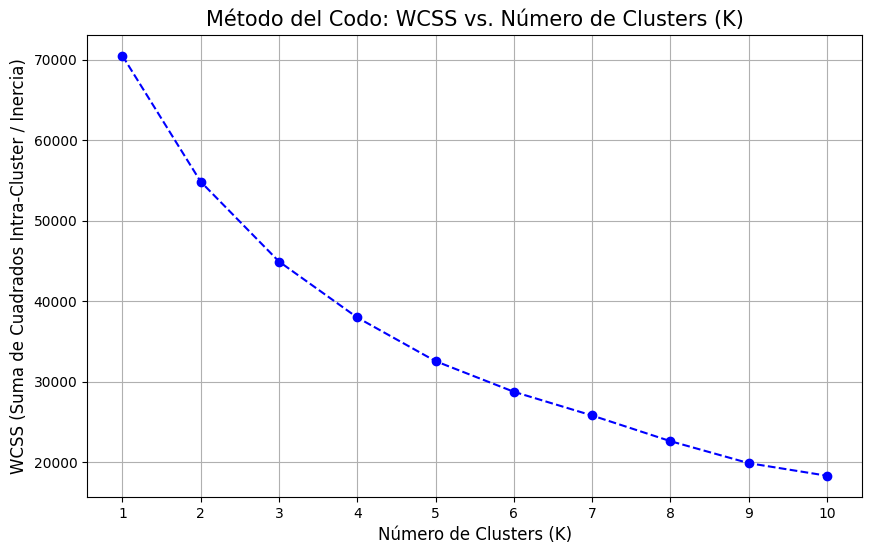

In [75]:
inercia = []
k_range = range(1, 11) 

for k in k_range:
    kmeans = KMeans(n_clusters=k, init='k-means++', max_iter=300, n_init=10, random_state=42)
    kmeans.fit(X_scaled)
    # Guardamos la inercia (WCSS) del modelo
    inercia.append(kmeans.inertia_)

#gráfico
plt.figure(figsize=(10, 6))
plt.plot(k_range, inercia, marker='o', linestyle='--', color='blue')
plt.title('Método del Codo: WCSS vs. Número de Clusters (K)', fontsize=15)
plt.xlabel('Número de Clusters (K)', fontsize=12)
plt.ylabel('WCSS (Suma de Cuadrados Intra-Cluster / Inercia)', fontsize=12)
plt.xticks(k_range)
plt.grid(True)
plt.show()

Evaluamos las métricas obtenidas a partir de distintos valores de K para decidir el número óptimo y poder visualizar la relación entre los valores de K y sus métricas.

Con K=2, el coeficiente de silueta es: 0.7525 y el índice de Davies-Bouldin es: 1.1782	
Con K=3, el coeficiente de silueta es: 0.6594 y el índice de Davies-Bouldin es: 1.1253	
Con K=4, el coeficiente de silueta es: 0.5762 y el índice de Davies-Bouldin es: 1.148	
Con K=5, el coeficiente de silueta es: 0.5873 y el índice de Davies-Bouldin es: 1.1257	
Con K=6, el coeficiente de silueta es: 0.5903 y el índice de Davies-Bouldin es: 0.9674	
Con K=7, el coeficiente de silueta es: 0.5945 y el índice de Davies-Bouldin es: 0.9562	


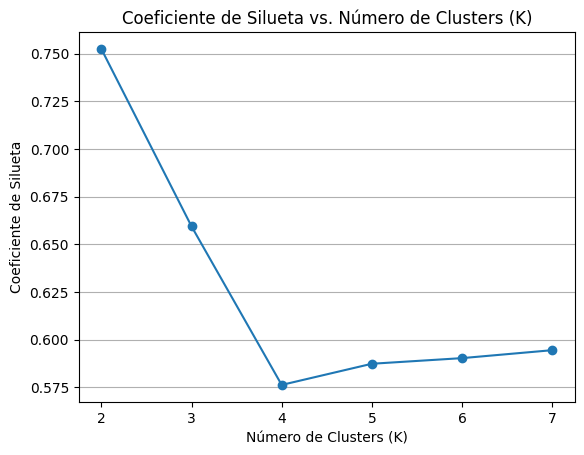

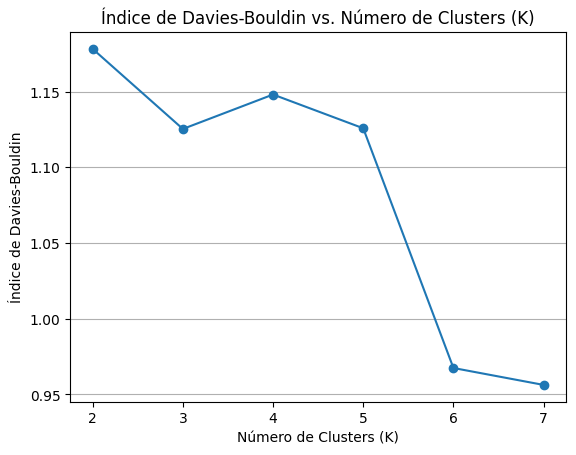

In [76]:
Ks = range(2, 8, 1)
siluetas = []
davies_bouldin_indice = []

for K in Ks:
    clusters_km = KMeans(
        n_clusters=K,
        init='k-means++',
        max_iter=300,
        n_init=10,
        random_state=42      
    ).fit(X_scaled)
    
    silueta_KM = silhouette_score(X_scaled, clusters_km.labels_)
    Db_index_KM = davies_bouldin_score(X_scaled, clusters_km.labels_)
    
    print(f"Con K={K}, el coeficiente de silueta es: {round(silueta_KM,4)} "
          f"y el índice de Davies-Bouldin es: {round(Db_index_KM,4)}\t")
    
    siluetas.append(silueta_KM)
    davies_bouldin_indice.append(Db_index_KM)

plt.plot(Ks, siluetas, marker='o', linestyle='-')
plt.title('Coeficiente de Silueta vs. Número de Clusters (K)')
plt.xlabel('Número de Clusters (K)')
plt.ylabel('Coeficiente de Silueta')
plt.xticks(Ks)
plt.grid(True, axis='y')
plt.show()

plt.plot(Ks, davies_bouldin_indice, marker='o', linestyle='-')
plt.title('Índice de Davies-Bouldin vs. Número de Clusters (K)')
plt.xlabel('Número de Clusters (K)')
plt.ylabel('Índice de Davies-Bouldin')
plt.xticks(Ks)
plt.grid(True, axis='y')
plt.show()


Decidimos quedarnos finalmente con K = 3 ya que a partir del método del codo es el punto donde la inercia deja de ser significativa, también porque arroja un valor bueno para datos reales con mucha variabilidad en el índice de silueta y respecto al DBI, arroja un valor relativamente bajo. 

In [77]:
k_opt = 3

#Entrenamos el modelo final de K-Means con K = 3
kmeans_final = KMeans(
    n_clusters=k_opt,
    init='k-means++',
    max_iter=300,
    n_init=10,
    random_state=42    
)
kmeans_final.fit(X_scaled)


labels_final = kmeans_final.labels_

datos = datos.copy()               
datos.loc[:, 'Cluster'] = labels_final

# Métricas para K = 3
silhouette_score_value = silhouette_score(X_scaled, labels_final)
davies_bouldin = davies_bouldin_score(X_scaled, labels_final)
inercia = kmeans_final.inertia_

print("📊 MÉTRICAS DE EVALUACIÓN PARA K = 3")
print("--------------------------------------")
print(f"✅ Coeficiente de Silueta:     {silhouette_score_value:.3f}  (↑ mejor)")
print(f"📉 Índice de Davies-Bouldin:  {davies_bouldin:.3f}  (↓ mejor)")
print(f"📐 Inercia (suma dist. cuad.): {inercia:.3f}  (↓ mejor)")


📊 MÉTRICAS DE EVALUACIÓN PARA K = 3
--------------------------------------
✅ Coeficiente de Silueta:     0.659  (↑ mejor)
📉 Índice de Davies-Bouldin:  1.125  (↓ mejor)
📐 Inercia (suma dist. cuad.): 44932.606  (↓ mejor)


Aplicamos una reducción de dimensionalidad utilizando el algoritmo PCA, para poder conservar la mayor varibilidad de los datos. 

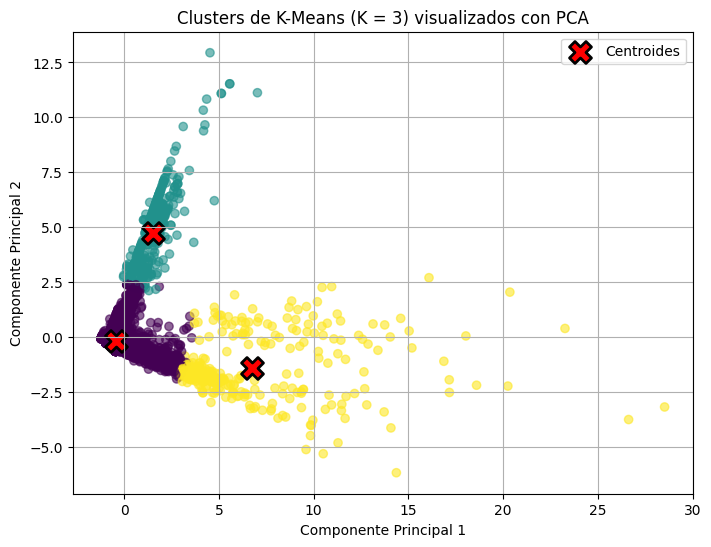


📈 Varianza explicada por cada componente:
PC1: 36.137%
PC2: 17.676%
Varianza explicada acumulada (PC1+PC2): 53.813%

🔎 LOADINGS (cargas) de cada variable en PC1 y PC2:
                    PC1       PC2
status_type    0.244297 -0.174958
num_reactions  0.286301  0.624803
num_comments   0.349168 -0.225759
num_shares     0.444831 -0.190033
num_likes      0.244151  0.656723
num_loves      0.462474 -0.145717
num_wows       0.294638  0.047012
num_hahas      0.309000 -0.117216
num_sads       0.162429 -0.107653
num_angrys     0.237465 -0.108961


In [78]:
# Ajustamos PCA sobre los mismos datos que usamos en K-Means
pca = PCA(n_components=2)
components = pca.fit_transform(X_scaled)   

# DataFrame con las dos componentes y el cluster asignado
db_plot = pd.DataFrame(components, columns=['PC1', 'PC2'])
db_plot['Cluster'] = labels_final        

# Proyectamos los centroides al espacio de PCA
centroids_pca = pca.transform(kmeans_final.cluster_centers_)

# Gráfico de los clusters en el plano PC1–PC2 con centroides
plt.figure(figsize=(8, 6))

# Puntos 
plt.scatter(
    db_plot['PC1'], db_plot['PC2'],
    c=db_plot['Cluster'], cmap='viridis', alpha=0.6
)

# Centroides
plt.scatter(
    centroids_pca[:, 0], centroids_pca[:, 1],
    c='red', s=250, marker='X', edgecolor='black', linewidths=2,
    label='Centroides'
)

plt.title('Clusters de K-Means (K = 3) visualizados con PCA')
plt.xlabel('Componente Principal 1')
plt.ylabel('Componente Principal 2')
plt.legend()
plt.grid(True)
plt.show()

# 5) Varianza explicada por cada componente
print("\n📈 Varianza explicada por cada componente:")
for i, var in enumerate(pca.explained_variance_ratio_, start=1):
    print(f"PC{i}: {var:.3%}")
print(f"Varianza explicada acumulada (PC1+PC2): {pca.explained_variance_ratio_.sum():.3%}")

# 6) LOADINGS: contribución de cada variable a PC1 y PC2
feature_names = X.columns   # X es 'datos' que usaste para escalar

loadings = pd.DataFrame(
    pca.components_.T,
    index=feature_names,
    columns=['PC1', 'PC2']
)

print("\n🔎 LOADINGS (cargas) de cada variable en PC1 y PC2:")
print(loadings)

Evaluamos las características de cada cluster haciendo un promedio de los datos y obteniendo los mínimos, máximos y su desviación estándar. 

In [79]:
datos.groupby("Cluster").agg(["mean", "max", "min"])

status_type           num_reactions            num_comments         \
               mean  max  min          mean   max  min         mean    max   
Cluster                                                                      
0          1.655897  3.0  0.0    113.706085   993    0    95.594103   4487   
1          1.542466  3.0  0.0   1839.621918  4710  976    62.054795   1186   
2          2.909385  3.0  1.0    730.983819  2639  156  3072.983819  20990   

             num_shares              num_likes              num_loves       \
        min        mean   max min         mean   max  min        mean  max   
Cluster                                                                      
0         0   20.040464   496   0   105.621236   981    0    7.023526  220   
1         0   11.660274   257   0  1833.789041  4710  962    3.128767   73   
2         3  485.841424  3424   0   560.776699  1766  103  141.789644  657   

              num_wows          num_hahas           num_sads          \
        min       mean  max min      mean  max min      mean max min   
Cluster                                                                
0         0   0.544385   38   0  0.317911   40   0  0.143821  28   0   
1         0   2.465753   65   0  0.200000   10   0  0.032877   3   0   
2         0  15.271845  278   0  9.093851  157   0  2.553398  51   0   

        num_angrys          
              mean max min  
Cluster                     
0         0.052227  10   0  
1         0.005479   1   0  
2         1.498382  31   0

cluster 0: 
Reactions mean: 113
Comments mean :95
shares mean: 20
likes mean: 105
loves: 7
wows:0.5
hahas:0.3
sads:0.14
angrys: 0.005

cluster 1: 
Reactions mean: 1839
Comments mean :62
shares mean: 11
likes mean: 1833
loves: 3.12
wows:2.4
hahas:0.2
sads:0.03
angrys: 0.005

cluster 2:
Reactions mean: 730
Comments mean :3072
shares mean: 485
likes mean: 560
loves: 141
wows:15.27
hahas:9.0
sads:2.5
angrys: 1.5

### INTERPRETACION DE LOS CLUSTERS -- QUE PUEDE SIGNIFICAR?

Cluster 0

Interacciones bajas a moderadas y bastante equilibradas: las reacciones (113) y los comentarios (95) están en proporciones similares. Representa publicaciones normales, orgánicas, de rendimiento promedio, donde la audiencia interactúa de forma estándar sin viralidad ni polémica. Podrían ser contenidos informativos o rutinarios que no generan ni rechazo ni entusiasmo masivo.

Cluster 1

Muchísimos likes (1833) pero muy pocos comentarios (62) y casi ningún share. Reactions ≈ likes. Esto indica publicaciones que generan aprobación rápida y superficial, típicas de contenido visual atractivo, mensajes positivos o anuncios donde la gente pone “me gusta” pero no siente necesidad de debatir ni compartir. Representa piezas con alto alcance visual, pero con poca profundidad de interacción.

Cluster 2

Comentarios extremadamente altos (3072) en relación con las reacciones (730). Esto indica publicaciones que generan mucha conversación, debate o polémica. Los usuarios interactúan más escribiendo que reaccionando. Suelen ser posts que provocan opiniones, discusiones, temas sensibles o contenido que invita explícitamente a comentar. También puede reflejar hilos largos de respuestas entre usuarios. Es el cluster donde la comunidad participa más activamente a nivel discursivo.

